 id  aire_px  perimetre_px     cx     cy  bbox_x  bbox_y  bbox_w  bbox_h  circularite  aspect_ratio
  1    28009        822.80 400.15 198.19     315      68     137     322        0.520         0.425
  2   145700       4613.86 243.78 465.99       0     148     452     530        0.086         0.853
 14       94         44.73 204.94 224.07     199     219      13      11        0.590         1.182
 15       57         31.80 325.74 235.59     320     231      12      10        0.708         1.200
 19      125         68.63 197.58 249.25     188     242      21      20        0.334         1.050
 20      223         90.87 190.68 265.58     176     256      30      20        0.339         1.500
 21      114         58.14 214.99 271.62     206     265      20      13        0.424         1.538
 22       55         32.24 330.86 271.06     326     268      12       7        0.665         1.714


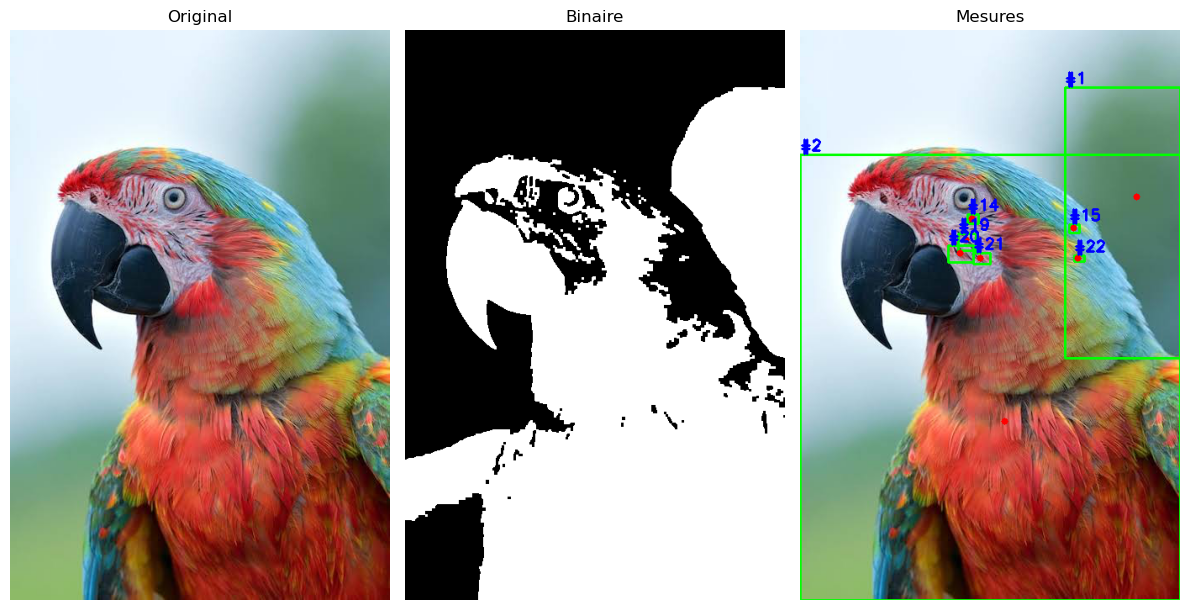

In [2]:
import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# ---------------------------------------------------------------
# 1. Charger une image contenant plusieurs objets
# ---------------------------------------------------------------
image = cv2.imread("./images.jpeg")           # BGR
gray  = cv2.cvtColor(image, cv2.COLOR_BGR2GRAY)

# ---------------------------------------------------------------
# 2. Image binaire (seuillage) — Otsu + inversion si nécessaire
# ---------------------------------------------------------------
_, binary = cv2.threshold(gray, 0, 255,
                          cv2.THRESH_BINARY_INV + cv2.THRESH_OTSU)

# Nettoyage morphologique (enlève le bruit)
kernel = np.ones((3, 3), np.uint8)
binary = cv2.morphologyEx(binary, cv2.MORPH_OPEN,  kernel, iterations=1)
binary = cv2.morphologyEx(binary, cv2.MORPH_CLOSE, kernel, iterations=1)

# ---------------------------------------------------------------
# 3. Détecter les composantes connexes
# ---------------------------------------------------------------
num_labels, labels, stats, centroids = cv2.connectedComponentsWithStats(
    binary, connectivity=8
)

# On ignore le label 0 = fond
objets = []
for i in range(1, num_labels):
    aire_px = stats[i, cv2.CC_STAT_AREA]
    if aire_px < 50:          # filtre les micro-objets
        continue

    # Masque du composant courant
    mask = (labels == i).astype(np.uint8) * 255

    # -----------------------------------------------------------
    # 4. Aire (déjà donnée par stats, mais on la recalcule proprement)
    # -----------------------------------------------------------
    aire = cv2.countNonZero(mask)

    # -----------------------------------------------------------
    # 5. Périmètre + centroïde
    # -----------------------------------------------------------
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL,
                                   cv2.CHAIN_APPROX_NONE)
    cnt = max(contours, key=cv2.contourArea)
    perimetre = cv2.arcLength(cnt, True)          # True = contour fermé

    # Centroïde : depuis cv2 (plus précis) ou via moments
    M = cv2.moments(cnt)
    cx = M["m10"] / M["m00"] if M["m00"] != 0 else centroids[i][0]
    cy = M["m01"] / M["m00"] if M["m00"] != 0 else centroids[i][1]

    # -----------------------------------------------------------
    # 6. Bounding box
    # -----------------------------------------------------------
    x, y, w, h = cv2.boundingRect(cnt)

    # -----------------------------------------------------------
    # 7. Circularité et aspect ratio
    # -----------------------------------------------------------
    circularite = (4 * np.pi * aire) / (perimetre ** 2) if perimetre > 0 else 0
    aspect_ratio = w / h if h > 0 else 0

    objets.append({
        "id":           i,
        "aire_px":      aire,
        "perimetre_px": round(perimetre, 2),
        "cx":           round(cx, 2),
        "cy":           round(cy, 2),
        "bbox_x":       x,
        "bbox_y":       y,
        "bbox_w":       w,
        "bbox_h":       h,
        "circularite":  round(circularite, 3),
        "aspect_ratio": round(aspect_ratio, 3),
    })

# ---------------------------------------------------------------
# 8. Tableau récapitulatif (1 ligne = 1 objet)
# ---------------------------------------------------------------
df = pd.DataFrame(objets)
print(df.to_string(index=False))
df.to_csv("mesures_objets.csv", index=False)

# ---------------------------------------------------------------
# Visualisation : bbox + centroïde + n° objet
# ---------------------------------------------------------------
vis = image.copy()
for o in objets:
    cv2.rectangle(vis,
                  (o["bbox_x"], o["bbox_y"]),
                  (o["bbox_x"] + o["bbox_w"], o["bbox_y"] + o["bbox_h"]),
                  (0, 255, 0), 2)
    cv2.circle(vis, (int(o["cx"]), int(o["cy"])), 4, (0, 0, 255), -1)
    cv2.putText(vis, f"#{o['id']}",
                (o["bbox_x"], o["bbox_y"] - 5),
                cv2.FONT_HERSHEY_SIMPLEX, 0.6, (255, 0, 0), 2)

plt.figure(figsize=(12, 6))
plt.subplot(1, 3, 1); plt.imshow(cv2.cvtColor(image, cv2.COLOR_BGR2RGB)); plt.title("Original"); plt.axis("off")
plt.subplot(1, 3, 2); plt.imshow(binary, cmap="gray");                   plt.title("Binaire"); plt.axis("off")
plt.subplot(1, 3, 3); plt.imshow(cv2.cvtColor(vis, cv2.COLOR_BGR2RGB));  plt.title("Mesures"); plt.axis("off")
plt.tight_layout(); plt.show()